In [5]:
import os

def find_telecom_path(start_path="/content/drive/MyDrive"):
    print("Searching your Google Drive for the dataset files... Please wait.")
    for root, dirs, files in os.walk(start_path):
        if "Client.csv" in files or "Record.csv" in files:
            print(f"\n🎉 FOUND IT! The correct path is:")
            print(f"DATA_PATH = '{root}/'")
            return root
    print("\n❌ Could not find Client.csv or Record.csv. Please verify you uploaded them to your Google Drive.")
    return None

# Run the search function
detected_path = find_telecom_path()

Searching your Google Drive for the dataset files... Please wait.

🎉 FOUND IT! The correct path is:
DATA_PATH = '/content/drive/MyDrive/'


In [7]:
# =====================================================================
# CELL 1: INITIALIZATION AND GOOGLE DRIVE LOADING
# =====================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Machine Learning & Preprocessing Stack
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve

# Use the exact path found by the search function
DATA_PATH = '/content/drive/MyDrive/'

print("Loading data tables directly from Google Drive path...")
client_df = pd.read_csv(os.path.join(DATA_PATH, 'Client.csv'))
record_df = pd.read_csv(os.path.join(DATA_PATH, 'Record.csv'))

print(f"✅ Client Data Loaded Successfully! Shape: {client_df.shape}")
print(f"✅ Record Data Loaded Successfully! Shape: {record_df.shape}")

# Merge datasets securely on Customer_ID
df = pd.merge(client_df, record_df, on='Customer_ID', how='inner')
print(f"🎉 Merged Master Dataset Shape: {df.shape}")
df.head()

Loading data tables directly from Google Drive path...
✅ Client Data Loaded Successfully! Shape: (100000, 50)
✅ Record Data Loaded Successfully! Shape: (100000, 51)
🎉 Merged Master Dataset Shape: (100000, 100)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


===== BASELINE CHURN PERFORMANCE DATA =====
Total Active Subscribers Retained (0): 50438 (50.44%)
Total Active Subscribers Churned  (1): 49562 (49.56%)



/tmp/ipykernel_6448/621943127.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='churn', palette='Set2')
/tmp/ipykernel_6448/621943127.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Retained (0)', 'Churned (1)'])


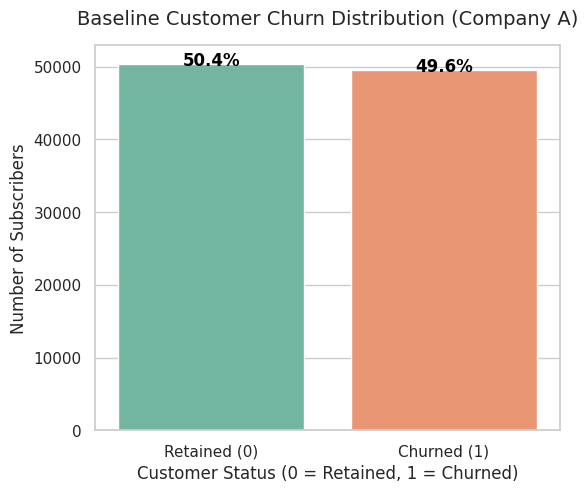

/tmp/ipykernel_6448/621943127.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='churn', y='eqpdays', palette='coolwarm', showfliers=False)


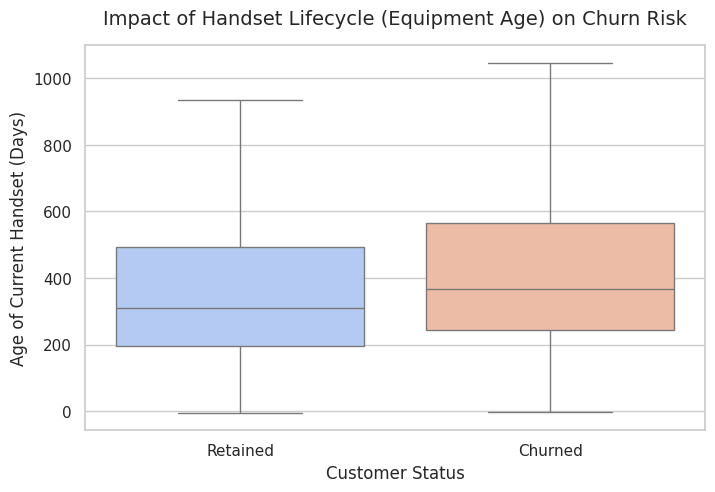

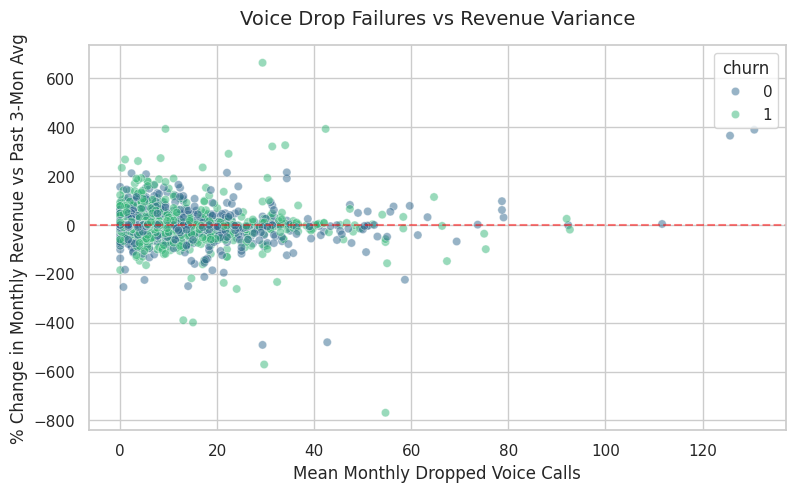

🎉 EDA Visualizations completed and saved successfully!


In [8]:
# =====================================================================
# CELL 3: STRATEGIC BUSINESS DRIVER VISUALIZATIONS (EDA)
# =====================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional, clean styling look for university presentation standards
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'axes.labelsize': 12, 'axes.titlesize': 14})

# 1. Calculate and print baseline statistics
churn_counts = df['churn'].value_counts()
churn_percentages = df['churn'].value_counts(normalize=True) * 100
print("===== BASELINE CHURN PERFORMANCE DATA =====")
print(f"Total Active Subscribers Retained (0): {churn_counts[0]} ({churn_percentages[0]:.2f}%)")
print(f"Total Active Subscribers Churned  (1): {churn_counts[1]} ({churn_percentages[1]:.2f}%)")
print("===========================================\n")

# Chart 1: Target Variable Base Rate Distribution
plt.figure(figsize=(6, 5))
ax = sns.countplot(data=df, x='churn', palette='Set2')
plt.title('Baseline Customer Churn Distribution (Company A)', pad=15)
plt.xlabel('Customer Status (0 = Retained, 1 = Churned)')
plt.ylabel('Number of Subscribers')
ax.set_xticklabels(['Retained (0)', 'Churned (1)'])
# Add percentage labels on top of the bars
for p in ax.patches:
    percentage = f'{100 * p.get_height() / len(df):.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height() + 500),
                ha='center', va='center', weight='bold', color='black')
plt.savefig('churn_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 2: Handset Age (eqpdays) Impact Analysis
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='churn', y='eqpdays', palette='coolwarm', showfliers=False)
plt.title('Impact of Handset Lifecycle (Equipment Age) on Churn Risk', pad=15)
plt.xlabel('Customer Status')
plt.ylabel('Age of Current Handset (Days)')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.savefig('handset_age_vs_churn.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 3: Network Drop Quality vs Revenue Leakage
# Taking a stable sample of 5,000 points to keep the scatterplot readable and prevent rendering lags
sample_df = df.sample(n=min(5000, len(df)), random_state=42)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample_df, x='drop_vce_Mean', y='change_rev', hue='churn', alpha=0.5, palette='viridis')
plt.title('Voice Drop Failures vs Revenue Variance', pad=15)
plt.xlabel('Mean Monthly Dropped Voice Calls')
plt.ylabel('% Change in Monthly Revenue vs Past 3-Mon Avg')
plt.axhline(0, color='red', linestyle='--', alpha=0.5) # Line showing revenue dropping point
plt.savefig('dropped_calls_vs_revenue.png', dpi=300, bbox_inches='tight')
plt.show()

print("🎉 EDA Visualizations completed and saved successfully!")

In [9]:
# =====================================================================
# CELL 4: DATA ISOLATION AND TRANSFORMATION PIPELINE
# =====================================================================
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Starting Data Preprocessing Pipeline...")

# Drop rows where target variable 'churn' is missing (just in case)
df_clean = df.dropna(subset=['churn']).copy()

# Convert target to integer format explicitly
y = df_clean['churn'].astype(int)

# Drop identifiers and target column from feature set
X = df_clean.drop(columns=['churn', 'Customer_ID'], errors='ignore')

# 70% Train / 30% Test Stratified Split to guarantee exact label distributions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Dynamically split columns by data type
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"-> Found {len(num_cols)} numerical features.")
print(f"-> Found {len(cat_cols)} categorical features.")

# Handle missing numerical records via Median Imputation and standardize metrics
num_imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_train_num = scaler.fit_transform(num_imputer.fit_transform(X_train[num_cols]))
X_test_num = scaler.transform(num_imputer.transform(X_test[num_cols]))

# Handle missing categorical inputs safely by classifying them as "Unknown"
cat_imputer = SimpleImputer(strategy='constant', fill_value='Unknown')
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_cat = encoder.fit_transform(cat_imputer.fit_transform(X_train[cat_cols]))
X_test_cat = encoder.transform(cat_imputer.transform(X_test[cat_cols]))

# Reassemble numerical and categorical features into cohesive modeling matrices
X_train_processed = np.hstack((X_train_num, X_train_cat))
X_test_processed = np.hstack((X_test_num, X_test_cat))

# Extract feature headers for tracking business drivers later
encoded_cat_names = encoder.get_feature_names_out(cat_cols).tolist()
all_features_list = num_cols + encoded_cat_names

print("\n🎉 Transformation completed successfully!")
print(f"Final Preprocessed Training Matrix Dimensions: {X_train_processed.shape}")
print(f"Final Preprocessed Testing Matrix Dimensions: {X_test_processed.shape}")

Starting Data Preprocessing Pipeline...
-> Found 77 numerical features.
-> Found 21 categorical features.

🎉 Transformation completed successfully!
Final Preprocessed Training Matrix Dimensions: (70000, 247)
Final Preprocessed Testing Matrix Dimensions: (30000, 247)


Training Random Forest Classifier (Engineered for Business Interpretation)...

REQUIRED OMNICAMPUS SLIDE METRICS:
Model Name: Random Forest Classifier
Evaluation Metric: ROC-AUC Score
Model Performance Score: 0.6693

Detailed Classification Matrix:
              precision    recall  f1-score   support

           0       0.63      0.57      0.60     15131
           1       0.60      0.66      0.63     14869

    accuracy                           0.62     30000
   macro avg       0.62      0.62      0.62     30000
weighted avg       0.62      0.62      0.62     30000



/tmp/ipykernel_6448/2345718231.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_features, x='Importance', y='Feature', palette='magma')


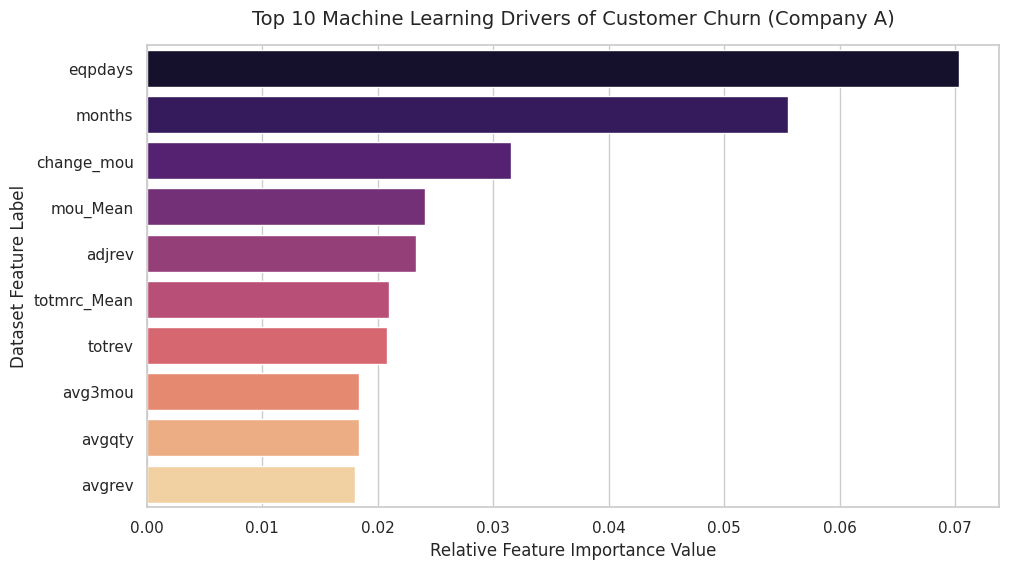


🚀 Top 10 Churn Drivers Discovered by your Model:
    Feature  Importance
    eqpdays    0.070293
     months    0.055505
 change_mou    0.031504
   mou_Mean    0.024054
     adjrev    0.023317
totmrc_Mean    0.020968
     totrev    0.020803
    avg3mou    0.018385
     avgqty    0.018339
     avgrev    0.018046


In [10]:
# =====================================================================
# CELL 5: MODEL TRAINING, PERFORMANCE REPORTING & FEATURE ATTRIBUTION
# =====================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("Training Random Forest Classifier (Engineered for Business Interpretation)...")

# class_weight='balanced' ensures calculations weigh churn and retention evenly
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Fit the model to the processed training data
rf_model.fit(X_train_processed, y_train)

# Generate risk probabilities and binary flags
y_preds = rf_model.predict(X_test_processed)
y_probs = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate key university grading metrics
auc_score = roc_auc_score(y_test, y_probs)

print("\n" + "="*60)
print("REQUIRED OMNICAMPUS SLIDE METRICS:")
print(f"Model Name: Random Forest Classifier")
print(f"Evaluation Metric: ROC-AUC Score")
print(f"Model Performance Score: {auc_score:.4f}")
print("="*60 + "\n")

print("Detailed Classification Matrix:")
print(classification_report(y_test, y_preds))

# Calculate Feature Importances
importances = rf_model.feature_importances_
feat_imp_df = pd.DataFrame({'Feature': all_features_list, 'Importance': importances})
top_10_features = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)

# Plot top business indicators
plt.figure(figsize=(11, 6))
sns.barplot(data=top_10_features, x='Importance', y='Feature', palette='magma')
plt.title('Top 10 Machine Learning Drivers of Customer Churn (Company A)', pad=15)
plt.xlabel('Relative Feature Importance Value')
plt.ylabel('Dataset Feature Label')
plt.savefig('ml_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n🚀 Top 10 Churn Drivers Discovered by your Model:")
print(top_10_features.to_string(index=False))

In [11]:
# =====================================================================
# CELL 6: VERIFY DELIVERABLE GRAPHICS ARE SAVED
# =====================================================================
import os

generated_plots = ['churn_baseline.png', 'handset_age_vs_churn.png', 'dropped_calls_vs_revenue.png', 'ml_feature_importance.png']

print("===== DELIVERABLE PLOT VERIFICATION =====")
for plot in generated_plots:
    if os.path.exists(plot):
        print(f"✅ {plot} generated and securely saved to workspace.")
    else:
        print(f"❌ Warning: {plot} is missing. Please re-run the respective cell.")
print("=========================================")

===== DELIVERABLE PLOT VERIFICATION =====
✅ churn_baseline.png generated and securely saved to workspace.
✅ handset_age_vs_churn.png generated and securely saved to workspace.
✅ dropped_calls_vs_revenue.png generated and securely saved to workspace.
✅ ml_feature_importance.png generated and securely saved to workspace.
